# 序列模型

In [61]:
%matplotlib inline
import torch
from torch import nn
from d2l import torch as d2l

tensor([ 0.0156,  0.0667, -0.0257,  0.3636, -0.0273, -0.0028,  0.1373, -0.1634,
        -0.0227,  0.2639])


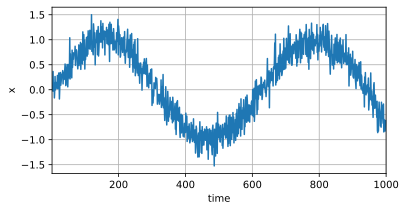

In [62]:
T = 1000  # 总共产生1000个点
time = torch.arange(1, T + 1, dtype=torch.float32)
x = torch.sin(0.01 * time) + torch.normal(0, 0.2, (T,))
print(x[:10])
d2l.plot(time, [x], 'time', 'x', xlim=[1, 1000], figsize=(6, 3))

In [63]:
tau = 4
features = torch.zeros((T - tau, tau))
for i in range(tau):
    features[:, i] = x[i: T - tau + i]
labels = x[tau:].reshape((-1, 1))

print(features[:10])
print(labels[:10])

batch_size, n_train = 16, 600
# 只有前n_train个样本用于训练
train_iter = d2l.load_array((features[:n_train], labels[:n_train]),
                            batch_size, is_train=True)

tensor([[ 0.0156,  0.0667, -0.0257,  0.3636],
        [ 0.0667, -0.0257,  0.3636, -0.0273],
        [-0.0257,  0.3636, -0.0273, -0.0028],
        [ 0.3636, -0.0273, -0.0028,  0.1373],
        [-0.0273, -0.0028,  0.1373, -0.1634],
        [-0.0028,  0.1373, -0.1634, -0.0227],
        [ 0.1373, -0.1634, -0.0227,  0.2639],
        [-0.1634, -0.0227,  0.2639, -0.0050],
        [-0.0227,  0.2639, -0.0050,  0.1494],
        [ 0.2639, -0.0050,  0.1494,  0.0228]])
tensor([[-0.0273],
        [-0.0028],
        [ 0.1373],
        [-0.1634],
        [-0.0227],
        [ 0.2639],
        [-0.0050],
        [ 0.1494],
        [ 0.0228],
        [ 0.0407]])


In [64]:
# 初始化网络权重的函数
def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.xavier_uniform_(m.weight)

# 一个简单的多层感知机
def get_net():
    net = nn.Sequential(nn.Linear(4, 10),
                        nn.ReLU(),
                        nn.Linear(10, 1))
    net.apply(init_weights)
    return net

# 平方损失。注意：MSELoss计算平方误差时不带系数1/2
loss = nn.MSELoss(reduction='none')

In [65]:
def train(net, train_iter, loss, epochs, lr):
    trainer = torch.optim.Adam(net.parameters(), lr)
    for epoch in range(epochs):
        for X, y in train_iter:
            trainer.zero_grad()
            l = loss(net(X), y)
            l.sum().backward()
            trainer.step()
        print(f'epoch {epoch + 1}, '
              f'loss: {d2l.evaluate_loss(net, train_iter, loss):f}')

net = get_net()
train(net, train_iter, loss, 5, 0.01)

epoch 1, loss: 0.049721
epoch 2, loss: 0.049923
epoch 3, loss: 0.049162
epoch 4, loss: 0.049967
epoch 5, loss: 0.055997


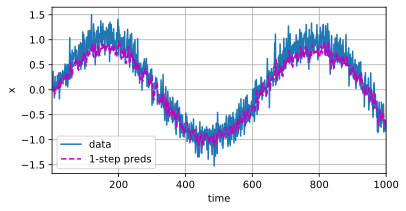

In [66]:
# 单步预测
onestep_preds = net(features)
d2l.plot([time, time[tau:]],
         [x.detach().numpy(), onestep_preds.detach().numpy()], 'time',
         'x', legend=['data', '1-step preds'], xlim=[1, 1000],
         figsize=(6, 3))

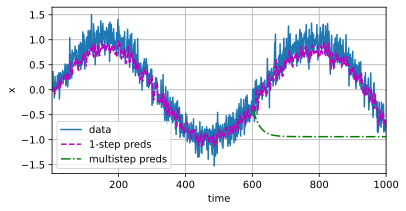

In [67]:
multistep_preds = torch.zeros(T)
multistep_preds[: n_train + tau] = x[: n_train + tau]
for i in range(n_train + tau, T):
    multistep_preds[i] = net(
        multistep_preds[i - tau:i].reshape((1, -1)))
d2l.plot([time, time[tau:], time[n_train + tau:]],
         [x.detach().numpy(), onestep_preds.detach().numpy(),
          multistep_preds[n_train + tau:].detach().numpy()], 'time',
         'x', legend=['data', '1-step preds', 'multistep preds'],
         xlim=[1, 1000], figsize=(6, 3))

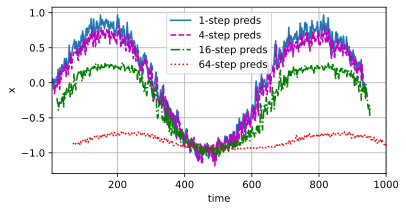

In [68]:
max_steps = 64

features = torch.zeros((T - tau - max_steps + 1, tau + max_steps))
# 列i（i<tau）是来自x的观测，其时间步从（i）到（i+T-tau-max_steps+1）
for i in range(tau):
    features[:, i] = x[i: i + T - tau - max_steps + 1]

# 列i（i>=tau）是来自（i-tau+1）步的预测，其时间步从（i）到（i+T-tau-max_steps+1）
for i in range(tau, tau + max_steps):
    features[:, i] = net(features[:, i - tau:i]).reshape(-1)

steps = (1, 4, 16, 64)
d2l.plot([time[tau + i - 1: T - max_steps + i] for i in steps],
         [features[:, (tau + i - 1)].detach().numpy() for i in steps], 'time', 'x',
         legend=[f'{i}-step preds' for i in steps], xlim=[5, 1000],
         figsize=(6, 3))